In [38]:
import pandas as pd
import numpy as np 
import tensorflow as tf 
from sklearn.model_selection import train_test_split 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense, Dropout, Input
import matplotlib.pyplot as plt

In [39]:
df = pd.read_csv("D:/Jupyter/DL/2/mnist_784_csv.csv")

In [40]:
df.shape

(70000, 785)

In [41]:
df.columns

Index(['pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7',
       'pixel8', 'pixel9', 'pixel10',
       ...
       'pixel776', 'pixel777', 'pixel778', 'pixel779', 'pixel780', 'pixel781',
       'pixel782', 'pixel783', 'pixel784', 'class'],
      dtype='object', length=785)

In [42]:
df

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784,class
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
69996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,3
69997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
69998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5


In [43]:
X=df.drop('class',axis=1).values
y=df['class'].values

In [44]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=int64)

In [45]:
X= X/255.0

In [46]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [47]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [48]:
X_train.shape

(56000, 784)

In [49]:
model=Sequential([Input(shape=(784,)),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')])

In [50]:
model.compile( optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'] )

In [51]:
history=model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
1400/1400 [==============================] - 3s 2ms/step - loss: 0.2668 - accuracy: 0.9216 - val_loss: 0.1522 - val_accuracy: 0.9556
Epoch 2/10
1400/1400 [==============================] - 3s 2ms/step - loss: 0.1098 - accuracy: 0.9663 - val_loss: 0.1144 - val_accuracy: 0.9655
Epoch 3/10
1400/1400 [==============================] - 2s 2ms/step - loss: 0.0745 - accuracy: 0.9771 - val_loss: 0.1013 - val_accuracy: 0.9693
Epoch 4/10
1400/1400 [==============================] - 3s 2ms/step - loss: 0.0555 - accuracy: 0.9831 - val_loss: 0.1011 - val_accuracy: 0.9691
Epoch 5/10
1400/1400 [==============================] - 2s 2ms/step - loss: 0.0435 - accuracy: 0.9856 - val_loss: 0.1135 - val_accuracy: 0.9641
Epoch 6/10
1400/1400 [==============================] - 2s 2ms/step - loss: 0.0334 - accuracy: 0.9889 - val_loss: 0.0903 - val_accuracy: 0.9744
Epoch 7/10
1400/1400 [==============================] - 3s 2ms/step - loss: 0.0273 - accuracy: 0.9911 - val_loss: 0.0992 - val_accuracy:

In [52]:
loss, accuracy = model.evaluate(X_test, y_test) 
print(f"Test Loss: {loss}, \nTest Accuracy: {accuracy}")

438/438 [==============================] - 1s 1ms/step - loss: 0.1300 - accuracy: 0.9701
Test Loss: 0.12999363243579865, 
Test Accuracy: 0.9700714349746704


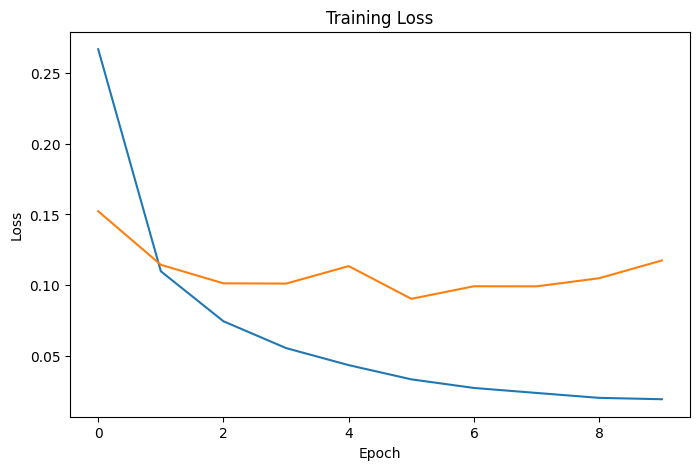

In [53]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()